# Figure 4 — Keloid application: calibrated prioritization
**A** permutation-null volcano (Hs27 TF screen). **B** external signature AUCs
with sample sizes. **C** candidate evidence tiers (j45 matrix).
Data: `j32_keloid_perm_null.csv`, `j28_signature_external_auc.csv`,
`j45_candidate_evidence_matrix.csv`.

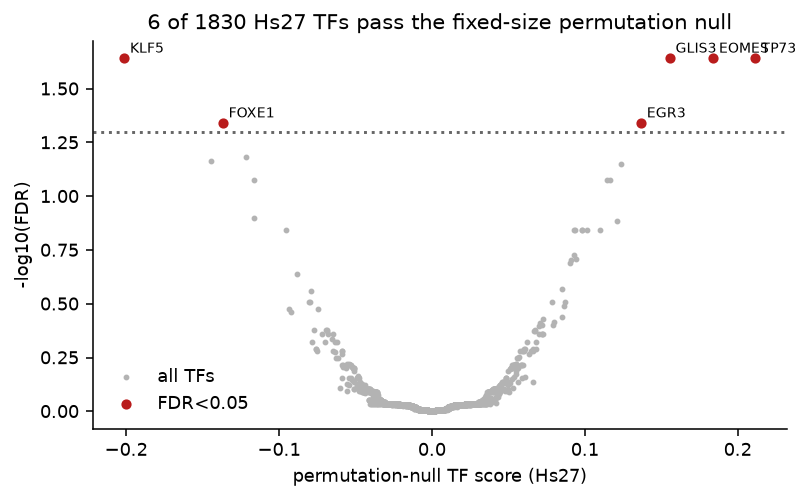

hits: ['EGR3', 'EOMES', 'FOXE1', 'GLIS3', 'KLF5', 'TP73']


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = os.path.join("..", "..", "results")
FIG = os.path.join("..", "..", "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300,
                     "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
MODELS = ["lw", "svd20", "moppca5", "nn10", "nn50"]
MODEL_LABELS = {"lw": "LW shrinkage", "svd20": "SVD-20",
                "moppca5": "moPPCA-5", "nn10": "centroid-10",
                "nn50": "centroid-50"}
CONTEXTS = [
    ("K562 essential", "j22_k562_foldfrozen_centroid.csv"),
    ("K562 GWPS", "j22_k562_gwps_foldfrozen_centroid.csv"),
    ("Norman", "j49_norman_foldfrozen.csv"),
    ("RPE1", "j49_rpe1_foldfrozen.csv"),
    ("sci-Plex3", "j49_sciplex3.csv"),
]
def load_ctx(name, fname):
    df = pd.read_csv(os.path.join(RES, fname))
    df["context"] = name
    return df

# ---- Panel A: permutation-null volcano ----
pn = pd.read_csv(os.path.join(RES, "j32_keloid_perm_null.csv"))
hs = pn[(pn.cell == "hs27") & (pn["variant"] == "full")].copy()
hs["mlog10"] = -np.log10(hs.fdr_perm.clip(lower=1e-6))
hits = hs[hs.fdr_perm < 0.05]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.scatter(hs.score, hs.mlog10, s=4, c="0.7", label="all TFs")
ax.scatter(hits.score, hits.mlog10, s=18, c="#b91c1c", label="FDR<0.05")
for _, r in hits.iterrows():
    ax.annotate(r.tf, (r.score, r.mlog10), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.axhline(-np.log10(0.05), color="0.4", ls=":")
ax.set_xlabel("permutation-null TF score (Hs27)")
ax.set_ylabel("-log10(FDR)")
ax.set_title(f"6 of {len(hs)} Hs27 TFs pass the fixed-size permutation null")
ax.legend(frameon=False)
fig.savefig(os.path.join(FIG, "fig4a_perm_volcano.png"), bbox_inches="tight")
plt.show()
print("hits:", sorted(hits.tf))


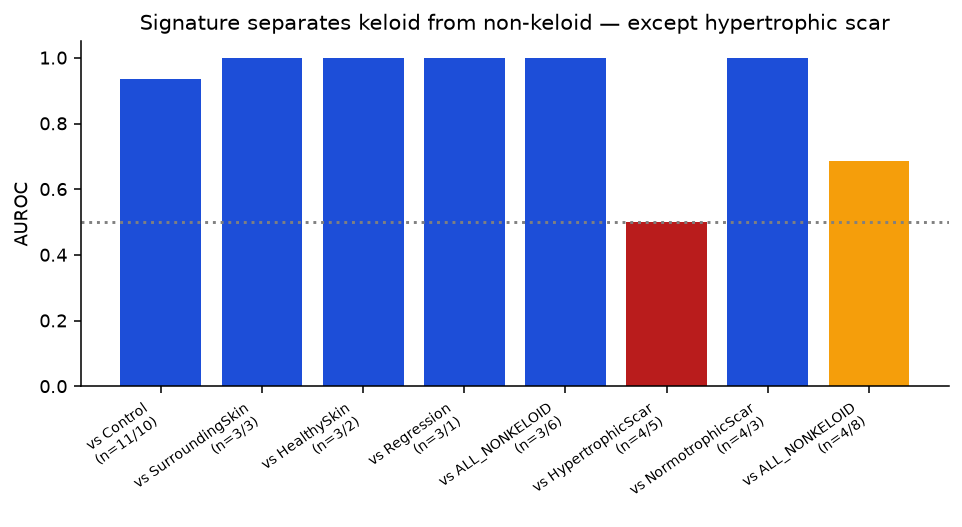

,cohort,contrast,auroc,n_pos,n_neg
0,DISCOVERY_21donor,Keloid_vs_Control,0.936364,11,10
1,GSE325137,Keloid_vs_SurroundingSkin,1.000000,3,3
2,GSE325137,Keloid_vs_HealthySkin,1.000000,3,2
3,GSE325137,Keloid_vs_Regression,1.000000,3,1
4,GSE325137,Keloid_vs_ALL_NONKELOID,1.000000,3,6
5,GSE188952,Keloid_vs_HypertrophicScar,0.500000,4,5
6,GSE188952,Keloid_vs_NormotrophicScar,1.000000,4,3
7,GSE188952,Keloid_vs_ALL_NONKELOID,0.687500,4,8


In [2]:

# ---- Panel B: external AUCs with n's ----
au = pd.read_csv(os.path.join(RES, "j28_signature_external_auc.csv"))
au["label"] = au.contrast.str.replace("Keloid_vs_", "vs ", regex=False) + \
              "\n(n=" + au.n_pos.astype(str) + "/" + au.n_neg.astype(str) + ")"
fig, ax = plt.subplots(figsize=(8.0, 3.2))
colors = ["#1d4ed8" if a > 0.9 else ("#b91c1c" if a < 0.6 else "#f59e0b")
          for a in au.auroc]
ax.bar(range(len(au)), au.auroc, color=colors)
ax.set_xticks(range(len(au)), au["label"], rotation=35, ha="right", fontsize=7)
ax.axhline(0.5, color="0.5", ls=":")
ax.set_ylabel("AUROC")
ax.set_title("Signature separates keloid from non-keloid — except hypertrophic scar")
fig.savefig(os.path.join(FIG, "fig4b_external_auc.png"), bbox_inches="tight")
plt.show()
au[["cohort","contrast","auroc","n_pos","n_neg"]]


In [3]:

# ---- Panel C: evidence tiers ----
ev = pd.read_csv(os.path.join(RES, "j45_candidate_evidence_matrix.csv"))
print(ev.evidence_tier.value_counts())
keep = ev[ev.evidence_tier.isin(["coloc-strong", "screen-permutation"])].copy()
cols = ["gene", "hs27_score", "coloc_PP_H4_max", "ag2_lfc_maxabs",
        "ag2_emp_q_dn", "ot_score", "evidence_tier"]
show = keep[[c for c in cols if c in keep.columns]].head(20)
show


evidence_tier
weak                  1048
AG2-only                 8
screen-permutation       6
coloc-strong             4
AG2-empirical            1
Name: count, dtype: int64


,gene,hs27_score,coloc_PP_H4_max,ag2_lfc_maxabs,ag2_emp_q_dn,ot_score,evidence_tier
0,SETBP1,NaN,0.9980,0.193654,0.000000,0.404530,coloc-strong
1,ASIP,NaN,0.9798,0.005942,0.395357,0.280925,coloc-strong
2,LSP1,NaN,0.9490,0.018063,0.439286,0.331717,coloc-strong
3,NEDD4,NaN,0.9485,0.001943,0.439286,0.507634,coloc-strong
26,GLIS3,0.155532,0.0000,0.001964,0.395357,0.283388,screen-permutation
78,TP73,0.211580,NaN,NaN,NaN,NaN,screen-permutation
79,EOMES,0.183913,NaN,NaN,NaN,NaN,screen-permutation
80,EGR3,0.136727,NaN,NaN,NaN,NaN,screen-permutation
198,FOXE1,-0.136774,NaN,NaN,NaN,NaN,screen-permutation
200,KLF5,-0.201288,NaN,NaN,NaN,NaN,screen-permutation
